# Data Preparation and Analysis — Red Wine Quality Dataset

**M.Tech Artificial Intelligence | Practical Assignment**

This notebook completes Steps 1–9 using the supplied `wineQualityReds.csv` file.

**How to run:** Keep this notebook and `wineQualityReds.csv` in the same folder, open the notebook in Jupyter Notebook/JupyterLab/VS Code, and select **Run All**. The notebook also checks `/mnt/data/` as a fallback location in hosted environments.

**Dataset:** Red Wine Quality (Portuguese Vinho Verde). The supplied file contains physicochemical measurements and a sensory quality score. The original Kaggle dataset page is listed below. The supplied file has an additional index-like column (`Unnamed: 0`), which is removed during cleaning.

## Step 1 — Dataset Collection

- **Dataset name:** Red Wine Quality (red wine subset)
- **Kaggle source:** https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009
- **Original research:** Cortez et al. (2009), *Modeling wine preferences by data mining from physicochemical properties*.
- **Description:** Each row represents a red wine sample. Eleven input variables describe physicochemical properties (acidity, sugar, chlorides, sulfur dioxide, density, pH, sulphates and alcohol). `quality` is the sensory score (integer scale in the supplied data).
- **Problem statement:** Explore which measured wine properties are associated with the sensory quality score and prepare a clean, analysis-ready dataset.
- **Objectives:** inspect and clean the data; summarize numerical and categorical information; identify relationships and outliers; visualize distributions and associations; engineer useful features; and provide evidence-based conclusions.

> The file name and its 1,599-row structure match the commonly distributed red-wine quality dataset. The notebook analyses the uploaded file itself; if your instructor expects a different Kaggle download page, replace the source URL above with the exact page you used.

## Setup — Install and import libraries
Run this cell once if any package is missing.

In [6]:
%pip install -q numpy pandas matplotlib seaborn plotly scikit-learn

In [7]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

# Find the uploaded CSV. Preferred: same folder as this notebook.
candidate_paths = [
    Path("wineQualityReds.csv"),
    Path("./data/wineQualityReds.csv"),
    Path("/mnt/data/wineQualityReds.csv"),
    Path("/content/drive/MyDrive/wineQualityReds.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find wineQualityReds.csv. Put the CSV in the same folder as this notebook "
        "or update DATA_PATH to its location."
    )

raw_df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Dataset shape: {raw_df.shape[0]} rows × {raw_df.shape[1]} columns")
display(raw_df.head())

Loaded: /content/drive/MyDrive/wineQualityReds.csv
Dataset shape: 1599 rows × 13 columns


,Unnamed: 0,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,1,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,2,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,3,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,4,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,5,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Step 2 — Python and NumPy

In [9]:
# Use numeric columns from the dataset to demonstrate NumPy operations.
numeric_columns_raw = raw_df.select_dtypes(include=np.number).columns.tolist()
numeric_array = raw_df[numeric_columns_raw].to_numpy(dtype=float)

print("NumPy array shape:", numeric_array.shape)
print("First 5 rows:\n", numeric_array[:5])

# Array creation, indexing, slicing and arithmetic
sample_array = np.array([2, 4, 6, 8, 10])
zeros_array = np.zeros(5)
ones_array = np.ones(5)
sequence_array = np.arange(1, 11)

print("\nCreated arrays:")
print("Sample:", sample_array)
print("Zeros:", zeros_array)
print("Ones:", ones_array)
print("Sequence:", sequence_array)
print("Index at position 2:", sample_array[2])
print("Slice positions 1 to 3:", sample_array[1:4])
print("Array + 5:", sample_array + 5)
print("Array × 2:", sample_array * 2)

# Descriptive statistics over the numeric data (column-wise)
print("\nColumn-wise NumPy statistics:")
print("Mean:", np.nanmean(numeric_array, axis=0))
print("Median:", np.nanmedian(numeric_array, axis=0))
print("Standard deviation:", np.nanstd(numeric_array, axis=0))
print("Minimum:", np.nanmin(numeric_array, axis=0))
print("Maximum:", np.nanmax(numeric_array, axis=0))
print("25th, 50th, 75th percentiles:\n", np.nanpercentile(numeric_array, [25, 50, 75], axis=0))

NumPy array shape: (1599, 13)
First 5 rows:
 [[1.000e+00 7.400e+00 7.000e-01 0.000e+00 1.900e+00 7.600e-02 1.100e+01
  3.400e+01 9.978e-01 3.510e+00 5.600e-01 9.400e+00 5.000e+00]
 [2.000e+00 7.800e+00 8.800e-01 0.000e+00 2.600e+00 9.800e-02 2.500e+01
  6.700e+01 9.968e-01 3.200e+00 6.800e-01 9.800e+00 5.000e+00]
 [3.000e+00 7.800e+00 7.600e-01 4.000e-02 2.300e+00 9.200e-02 1.500e+01
  5.400e+01 9.970e-01 3.260e+00 6.500e-01 9.800e+00 5.000e+00]
 [4.000e+00 1.120e+01 2.800e-01 5.600e-01 1.900e+00 7.500e-02 1.700e+01
  6.000e+01 9.980e-01 3.160e+00 5.800e-01 9.800e+00 6.000e+00]
 [5.000e+00 7.400e+00 7.000e-01 0.000e+00 1.900e+00 7.600e-02 1.100e+01
  3.400e+01 9.978e-01 3.510e+00 5.600e-01 9.400e+00 5.000e+00]]

Created arrays:
Sample: [ 2  4  6  8 10]
Zeros: [0. 0. 0. 0. 0.]
Ones: [1. 1. 1. 1. 1.]
Sequence: [ 1  2  3  4  5  6  7  8  9 10]
Index at position 2: 6
Slice positions 1 to 3: [4 6 8]
Array + 5: [ 7  9 11 13 15]
Array × 2: [ 4  8 12 16 20]

Column-wise NumPy statistics:
Mean: 

## Step 3 — Pandas Operations

In [10]:
print("First five records:")
display(raw_df.head())
print("Last five records:")
display(raw_df.tail())

print("Rows and columns:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())

print("\nData types:")
display(raw_df.dtypes.to_frame("Data type"))

print("\nSummary statistics:")
display(raw_df.describe(include="all").T)

print("\nMissing values by column:")
display(raw_df.isna().sum().to_frame("Missing values"))

print("Duplicate rows:", raw_df.duplicated().sum())

First five records:


,Unnamed: 0,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,1,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,2,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,3,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,4,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,5,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Last five records:


,Unnamed: 0,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
1594,1595,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,1596,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,1597,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,1598,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,1599,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


Rows and columns: (1599, 13)

Column names:
['Unnamed: 0', 'fixed.acidity', 'volatile.acidity', 'citric.acid', 'residual.sugar', 'chlorides', 'free.sulfur.dioxide', 'total.sulfur.dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types:


,Data type
Unnamed: 0,int64
fixed.acidity,float64
volatile.acidity,float64
citric.acid,float64
residual.sugar,float64
chlorides,float64
free.sulfur.dioxide,float64
total.sulfur.dioxide,float64
density,float64
pH,float64



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1599.0,800.000000,461.735855,1.00000,400.5000,800.00000,1199.500000,1599.00000
fixed.acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile.acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric.acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual.sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free.sulfur.dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total.sulfur.dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000



Missing values by column:


,Missing values
Unnamed: 0,0
fixed.acidity,0
volatile.acidity,0
citric.acid,0
residual.sugar,0
chlorides,0
free.sulfur.dioxide,0
total.sulfur.dioxide,0
density,0
pH,0


Duplicate rows: 0


## Step 4 — Data Cleaning and Preprocessing

Cleaning decisions:
1. Work on a copy so the original data remains available for comparison.
2. Remove the index-like `Unnamed: 0` column, if present.
3. Standardize column names to lowercase with underscores.
4. Convert columns to numeric where possible.
5. Fill missing numeric values with the median (if any are present).
6. Remove exact duplicate rows.
7. Detect outliers with the IQR rule. For a robust analysis-ready copy, cap predictor outliers at the IQR bounds; retain the original quality target unchanged. Outliers are not automatically errors, so this capping is a preprocessing choice rather than proof that values were invalid.

In [11]:
df_clean = raw_df.copy()
rows_before, cols_before = df_clean.shape

# Remove an exported row-number/index column if present.
index_like_cols = [c for c in df_clean.columns if c.lower().startswith("unnamed:")]
df_clean = df_clean.drop(columns=index_like_cols, errors="ignore")

# Standardize column names.
df_clean.columns = (
    df_clean.columns.str.strip().str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Convert values to numeric where possible.
for col in df_clean.columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Missing-value handling.
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
missing_before = df_clean.isna().sum()
for col in numeric_cols:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Remove exact duplicates.
duplicates_before = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Detect and cap outliers in predictor columns only (do not cap target quality).
target_col = "quality"
predictor_cols = [c for c in df_clean.select_dtypes(include=np.number).columns if c != target_col]

outlier_counts = {}
for col in predictor_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_counts[col] = int(((df_clean[col] < lower) | (df_clean[col] > upper)).sum())
    df_clean[col] = df_clean[col].clip(lower, upper)

# Capping can make previously different extreme rows identical; remove any such duplicates too.
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Before cleaning:", raw_df.shape)
print("After cleaning:", df_clean.shape)
print("Index-like columns removed:", index_like_cols)
print("Exact duplicates removed:", duplicates_before)
print("\nMissing values before cleaning:")
display(missing_before.to_frame("Missing before"))
print("\nOutlier counts detected before capping:")
display(pd.Series(outlier_counts, name="IQR outliers").to_frame())
print("\nMissing values after cleaning:", int(df_clean.isna().sum().sum()))
print("Duplicate rows after cleaning:", int(df_clean.duplicated().sum()))
display(df_clean.head())

Before cleaning: (1599, 13)
After cleaning: (1356, 12)
Index-like columns removed: ['Unnamed: 0']
Exact duplicates removed: 240

Missing values before cleaning:


,Missing before
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
ph,0
sulphates,0



Outlier counts detected before capping:


,IQR outliers
fixed_acidity,41
volatile_acidity,19
citric_acid,1
residual_sugar,126
chlorides,87
free_sulfur_dioxide,26
total_sulfur_dioxide,45
density,35
ph,28
sulphates,55



Missing values after cleaning: 0
Duplicate rows after cleaning: 0


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


In [12]:
# Before/after comparison
comparison = pd.DataFrame({
    "Measure": ["Rows", "Columns", "Missing cells", "Duplicate rows"],
    "Before cleaning": [
        raw_df.shape[0], raw_df.shape[1],
        int(raw_df.isna().sum().sum()), int(raw_df.duplicated().sum())
    ],
    "After cleaning": [
        df_clean.shape[0], df_clean.shape[1],
        int(df_clean.isna().sum().sum()), int(df_clean.duplicated().sum())
    ]
})
display(comparison)

,Measure,Before cleaning,After cleaning
0,Rows,1599,1356
1,Columns,13,12
2,Missing cells,0,0
3,Duplicate rows,0,0


## Step 5 — Exploratory Data Analysis (EDA)

In [13]:
print("Descriptive statistics:")
display(df_clean.describe().T)

print("\nQuality score counts:")
display(df_clean["quality"].value_counts().sort_index().to_frame("Number of wines"))

# Numerical and categorical summaries
display(df_clean.select_dtypes(include=np.number).skew().to_frame("Skewness"))
quality_group_summary = df_clean.groupby("quality").agg(
    sample_count=("quality", "size"),
    mean_alcohol=("alcohol", "mean"),
    mean_volatile_acidity=("volatile_acidity", "mean"),
    mean_sulphates=("sulphates", "mean")
)
display(quality_group_summary)

corr = df_clean.select_dtypes(include=np.number).corr()
display(corr.round(3))

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1356.0,8.283555,1.654457,4.60000,7.1000,7.9000,9.20000,12.35000
volatile_acidity,1356.0,0.527965,0.177314,0.12000,0.3900,0.5200,0.64000,1.01500
citric_acid,1356.0,0.271947,0.195141,0.00000,0.0900,0.2600,0.43000,0.94000
residual_sugar,1356.0,2.322235,0.606081,0.90000,1.9000,2.2000,2.60000,3.65000
chlorides,1356.0,0.081361,0.018461,0.03850,0.0700,0.0790,0.09100,0.12250
free_sulfur_dioxide,1356.0,15.702434,9.844536,1.00000,7.0000,14.0000,21.00000,42.00000
total_sulfur_dioxide,1356.0,46.020280,30.810176,6.00000,22.0000,38.0000,63.00000,124.50000
density,1356.0,0.996709,0.001789,0.99227,0.9956,0.9967,0.99782,1.00115
ph,1356.0,3.309222,0.149433,2.92500,3.2100,3.3100,3.40000,3.68500
sulphates,1356.0,0.649830,0.137339,0.33000,0.5500,0.6200,0.73000,1.00000



Quality score counts:


,Number of wines
quality,
3,10
4,53
5,576
6,535
7,165
8,17


,Skewness
fixed_acidity,0.675961
volatile_acidity,0.459756
citric_acid,0.305206
residual_sugar,0.834254
chlorides,0.492746
free_sulfur_dioxide,0.855329
total_sulfur_dioxide,0.979110
density,0.011834
ph,0.078182
sulphates,0.820920


,sample_count,mean_alcohol,mean_volatile_acidity,mean_sulphates
quality,,,,
3,10,9.955000,0.810500,0.570000
4,53,10.265094,0.687830,0.573774
5,576,9.884028,0.576519,0.612431
6,535,10.655888,0.496028,0.667869
7,165,11.468788,0.403879,0.738909
8,17,12.100000,0.427647,0.768824


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
fixed_acidity,1.000,-0.270,0.674,0.212,0.215,-0.142,-0.107,0.668,-0.693,0.227,-0.069,0.125
volatile_acidity,-0.270,1.000,-0.561,0.040,0.140,-0.011,0.092,0.018,0.250,-0.313,-0.205,-0.391
citric_acid,0.674,-0.561,1.000,0.175,0.149,-0.051,0.028,0.364,-0.553,0.349,0.106,0.229
residual_sugar,0.212,0.040,0.175,1.000,0.199,0.078,0.151,0.412,-0.091,0.019,0.107,0.018
chlorides,0.215,0.140,0.149,0.199,1.000,-0.004,0.113,0.401,-0.265,0.129,-0.303,-0.190
free_sulfur_dioxide,-0.142,-0.011,-0.051,0.078,-0.004,1.000,0.685,-0.020,0.062,0.051,-0.084,-0.055
total_sulfur_dioxide,-0.107,0.092,0.028,0.151,0.113,0.685,1.000,0.113,-0.066,-0.005,-0.252,-0.203
density,0.668,0.018,0.364,0.412,0.401,-0.020,0.113,1.000,-0.347,0.159,-0.507,-0.180
ph,-0.693,0.250,-0.553,-0.091,-0.265,0.062,-0.066,-0.347,1.000,-0.158,0.205,-0.061
sulphates,0.227,-0.313,0.349,0.019,0.129,0.051,-0.005,0.159,-0.158,1.000,0.156,0.331


In [14]:
# Generate at least five observations from the actual data.
quality_counts = df_clean["quality"].value_counts()
most_common_quality = int(quality_counts.idxmax())
mean_quality = df_clean["quality"].mean()
alcohol_corr = df_clean["alcohol"].corr(df_clean["quality"])
volatile_corr = df_clean["volatile_acidity"].corr(df_clean["quality"])
sulphates_corr = df_clean["sulphates"].corr(df_clean["quality"])
density_corr = df_clean["density"].corr(df_clean["quality"])
top_quality = df_clean.groupby("quality")["alcohol"].mean()

observations = [
    f"The most frequent quality score is {most_common_quality}, representing {quality_counts.max()} samples ({quality_counts.max()/len(df_clean):.1%} of the cleaned dataset).",
    f"The average wine quality score is {mean_quality:.2f}.",
    f"Alcohol and quality have a Pearson correlation of {alcohol_corr:.3f}; this indicates the direction and strength of a linear association, not causation.",
    f"Volatile acidity and quality have a Pearson correlation of {volatile_corr:.3f}.",
    f"Sulphates and quality have a Pearson correlation of {sulphates_corr:.3f}.",
    f"Density and quality have a Pearson correlation of {density_corr:.3f}.",
    f"Mean alcohol content ranges from {top_quality.min():.2f}% to {top_quality.max():.2f}% across observed quality scores."
]
for i, item in enumerate(observations[:7], 1):
    print(f"{i}. {item}")

1. The most frequent quality score is 5, representing 576 samples (42.5% of the cleaned dataset).
2. The average wine quality score is 5.62.
3. Alcohol and quality have a Pearson correlation of 0.481; this indicates the direction and strength of a linear association, not causation.
4. Volatile acidity and quality have a Pearson correlation of -0.391.
5. Sulphates and quality have a Pearson correlation of 0.331.
6. Density and quality have a Pearson correlation of -0.180.
7. Mean alcohol content ranges from 9.88% to 12.10% across observed quality scores.


## Step 6 — Data Visualization Using Matplotlib

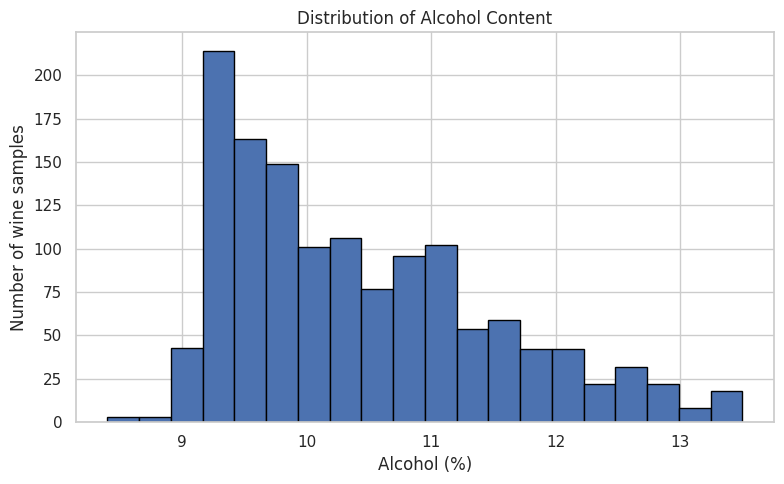

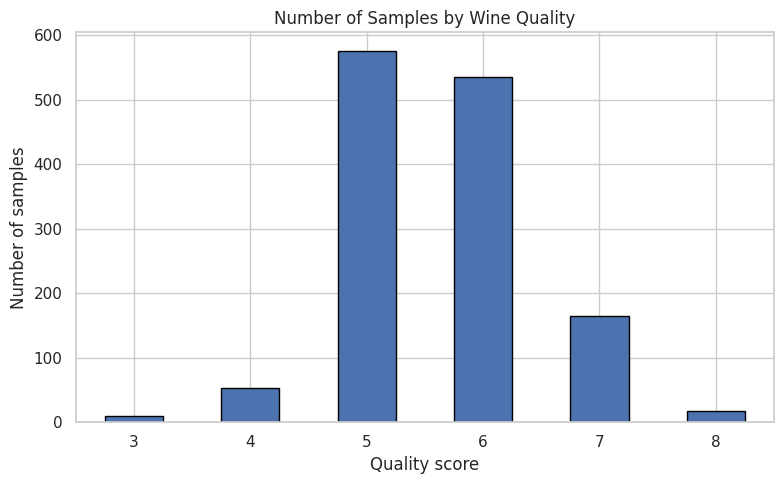

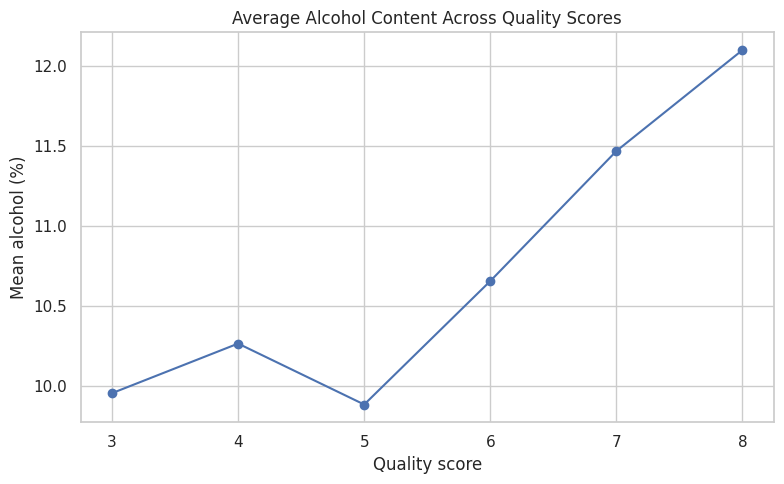

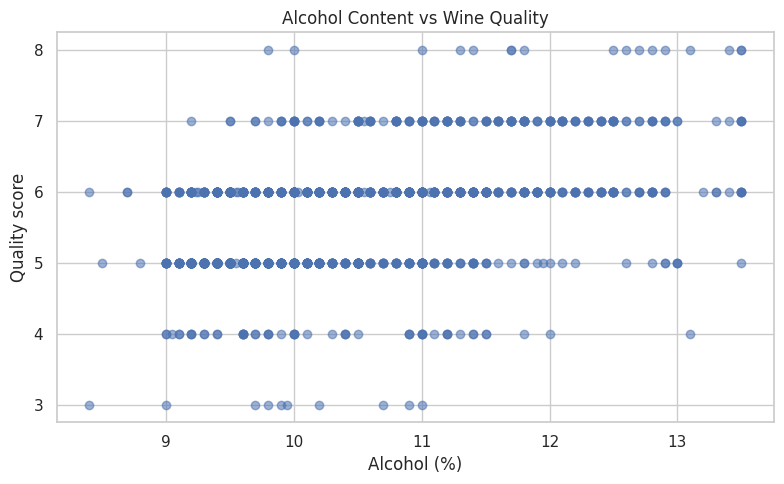

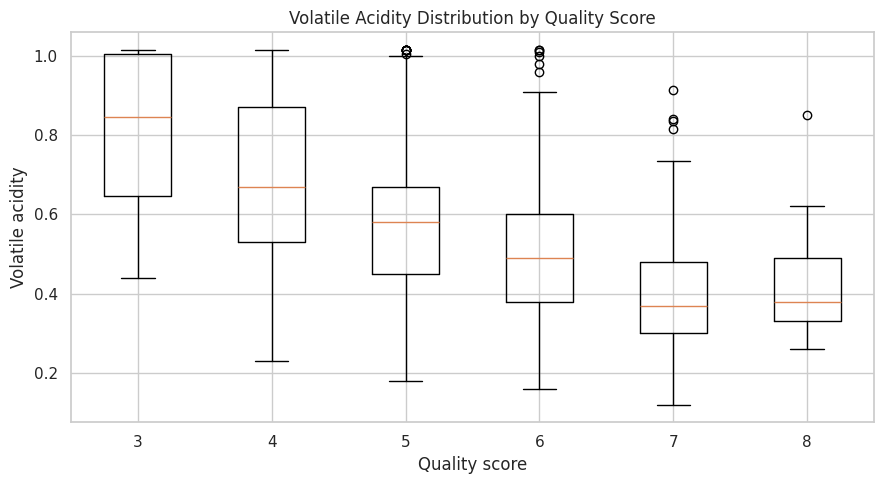

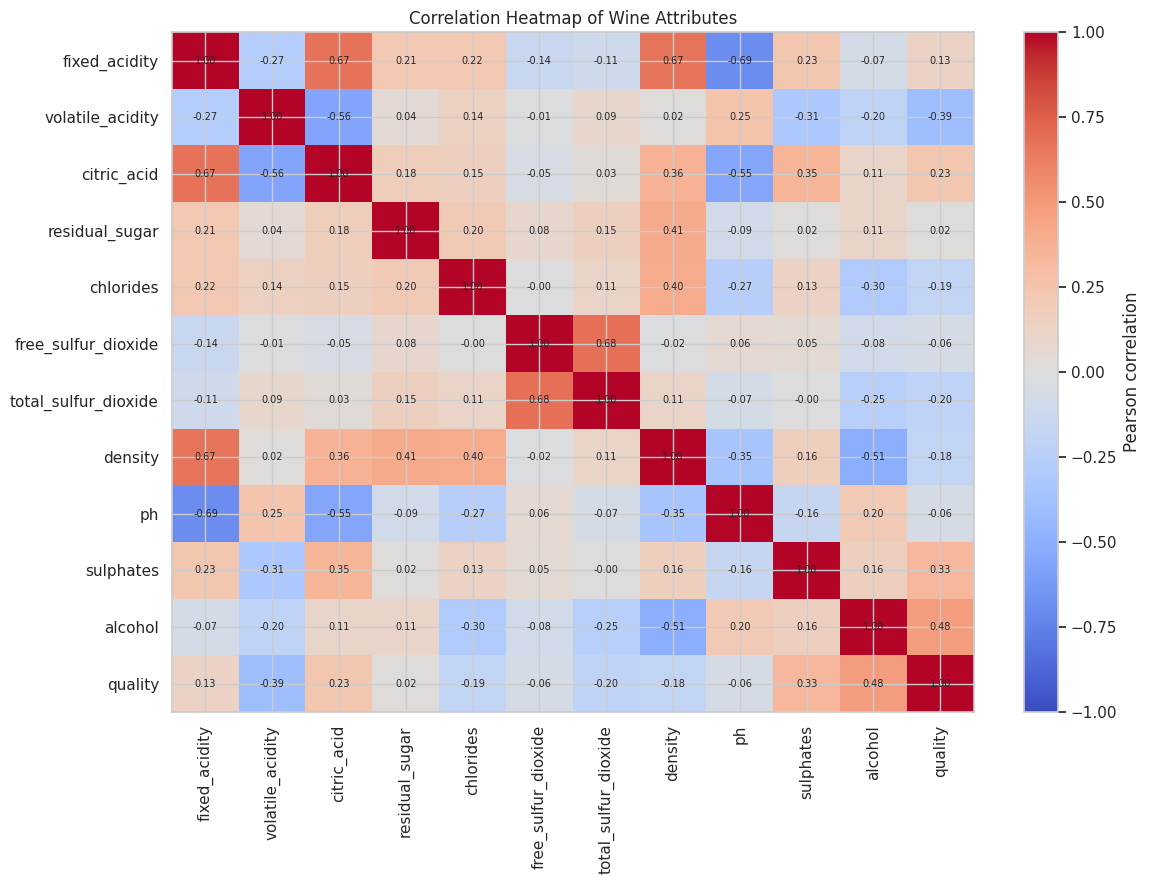

In [15]:
# 1. Histogram
plt.figure(figsize=(8, 5))
plt.hist(df_clean["alcohol"], bins=20, edgecolor="black")
plt.title("Distribution of Alcohol Content")
plt.xlabel("Alcohol (%)")
plt.ylabel("Number of wine samples")
plt.tight_layout()
plt.show()

# 2. Bar chart
plt.figure(figsize=(8, 5))
quality_counts.sort_index().plot(kind="bar", edgecolor="black")
plt.title("Number of Samples by Wine Quality")
plt.xlabel("Quality score")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Line chart — mean alcohol by quality score
mean_alcohol_by_quality = df_clean.groupby("quality")["alcohol"].mean().sort_index()
plt.figure(figsize=(8, 5))
plt.plot(mean_alcohol_by_quality.index, mean_alcohol_by_quality.values, marker="o")
plt.title("Average Alcohol Content Across Quality Scores")
plt.xlabel("Quality score")
plt.ylabel("Mean alcohol (%)")
plt.xticks(mean_alcohol_by_quality.index)
plt.tight_layout()
plt.show()

# 4. Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df_clean["alcohol"], df_clean["quality"], alpha=0.55)
plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Alcohol (%)")
plt.ylabel("Quality score")
plt.tight_layout()
plt.show()

# 5. Box plot
quality_values = sorted(df_clean["quality"].unique())
box_data = [df_clean.loc[df_clean["quality"] == q, "volatile_acidity"].dropna() for q in quality_values]
plt.figure(figsize=(9, 5))
plt.boxplot(box_data, labels=quality_values)
plt.title("Volatile Acidity Distribution by Quality Score")
plt.xlabel("Quality score")
plt.ylabel("Volatile acidity")
plt.tight_layout()
plt.show()

# 6. Correlation heatmap (Matplotlib)
plt.figure(figsize=(12, 9))
im = plt.imshow(corr, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Heatmap of Wine Attributes")
for row in range(corr.shape[0]):
    for col in range(corr.shape[1]):
        plt.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center", fontsize=7)
plt.tight_layout()
plt.show()

## Step 7 — Interactive Visualization Using Plotly

In [16]:
# Interactive histogram
fig = px.histogram(
    df_clean, x="alcohol", nbins=25, color="quality",
    title="Interactive Distribution of Alcohol by Quality",
    labels={"alcohol": "Alcohol (%)", "count": "Number of samples", "quality": "Quality score"},
    hover_data=["quality"]
)
fig.update_layout(xaxis_title="Alcohol (%)", yaxis_title="Number of samples", legend_title="Quality")
fig.show()

# Interactive scatter plot
fig = px.scatter(
    df_clean, x="alcohol", y="quality", color="volatile_acidity",
    size="sulphates", hover_data=["fixed_acidity", "citric_acid", "density"],
    title="Interactive Relationship: Alcohol and Wine Quality",
    labels={"alcohol": "Alcohol (%)", "quality": "Quality score",
            "volatile_acidity": "Volatile acidity", "sulphates": "Sulphates"}
)
fig.show()

# Interactive bar chart
quality_bar = df_clean["quality"].value_counts().sort_index().rename_axis("quality").reset_index(name="samples")
fig = px.bar(
    quality_bar, x="quality", y="samples", text="samples",
    title="Interactive Number of Wine Samples by Quality",
    labels={"quality": "Quality score", "samples": "Number of samples"},
    hover_data=["samples"]
)
fig.update_traces(textposition="outside")
fig.show()

In [17]:
print("Interpretation of interactive charts:")
print(f"- Histogram: the observed alcohol distribution is summarized above; the most common quality score is {most_common_quality}.")
print(f"- Scatter plot: the alcohol-quality linear correlation is {alcohol_corr:.3f}; inspect the point cloud for spread and overlap between scores.")
print("- Bar chart: bar heights show the frequency of each quality score; uneven counts mean some scores are much more represented than others.")

Interpretation of interactive charts:
- Histogram: the observed alcohol distribution is summarized above; the most common quality score is 5.
- Scatter plot: the alcohol-quality linear correlation is 0.481; inspect the point cloud for spread and overlap between scores.
- Bar chart: bar heights show the frequency of each quality score; uneven counts mean some scores are much more represented than others.


## Step 8 — Feature Engineering

Three additional features are created:
1. `total_acidity`: sum of fixed, volatile and citric acidity; a combined acidity measure.
2. `free_to_total_so2_ratio`: proportion of total sulfur dioxide that is free; a relative sulfur dioxide measure.
3. `alcohol_band`: low, medium or high alcohol group based on the sample's alcohol distribution (tertiles).

The categorical `alcohol_band` is one-hot encoded. Numerical features are standardized using `StandardScaler`. Scaling is demonstrated for analysis/model preparation; fit scaling on training data only if you later build a predictive model. There are no date/time columns in this dataset, so date extraction is not applicable.

In [18]:
feature_df = df_clean.copy()

feature_df["total_acidity"] = (
    feature_df["fixed_acidity"] + feature_df["volatile_acidity"] + feature_df["citric_acid"]
)

denominator = feature_df["total_sulfur_dioxide"].replace(0, np.nan)
feature_df["free_to_total_so2_ratio"] = (
    feature_df["free_sulfur_dioxide"] / denominator
).fillna(0)

# Use rank-based qcut so ties do not prevent creation of three groups.
feature_df["alcohol_band"] = pd.qcut(
    feature_df["alcohol"].rank(method="first"),
    q=3, labels=["Low", "Medium", "High"]
)

print("Engineered features preview:")
display(feature_df[[
    "fixed_acidity", "volatile_acidity", "citric_acid", "total_acidity",
    "free_sulfur_dioxide", "total_sulfur_dioxide", "free_to_total_so2_ratio",
    "alcohol", "alcohol_band"
]].head())

# Categorical encoding
encoded_df = pd.get_dummies(feature_df, columns=["alcohol_band"], drop_first=True, dtype=int)
print("One-hot encoded columns:")
print([c for c in encoded_df.columns if c.startswith("alcohol_band_")])

# Numerical scaling of predictors (exclude target).
scale_cols = encoded_df.select_dtypes(include=np.number).columns.drop("quality", errors="ignore").tolist()
scaler = StandardScaler()
scaled_features = pd.DataFrame(
    scaler.fit_transform(encoded_df[scale_cols]),
    columns=[f"{c}_scaled" for c in scale_cols],
    index=encoded_df.index
)

analysis_ready_df = pd.concat([encoded_df, scaled_features], axis=1)
print("Analysis-ready dataset shape:", analysis_ready_df.shape)
display(analysis_ready_df.head())

Engineered features preview:


,fixed_acidity,volatile_acidity,citric_acid,total_acidity,free_sulfur_dioxide,total_sulfur_dioxide,free_to_total_so2_ratio,alcohol,alcohol_band
0,7.4,0.70,0.00,8.10,11.0,34.0,0.323529,9.4,Low
1,7.8,0.88,0.00,8.68,25.0,67.0,0.373134,9.8,Medium
2,7.8,0.76,0.04,8.60,15.0,54.0,0.277778,9.8,Medium
3,11.2,0.28,0.56,12.04,17.0,60.0,0.283333,9.8,Medium
4,7.4,0.66,0.00,8.06,13.0,40.0,0.325000,9.4,Low


One-hot encoded columns:
['alcohol_band_Medium', 'alcohol_band_High']
Analysis-ready dataset shape: (1356, 31)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,total_acidity,free_to_total_so2_ratio,alcohol_band_Medium,alcohol_band_High,fixed_acidity_scaled,volatile_acidity_scaled,citric_acid_scaled,residual_sugar_scaled,chlorides_scaled,free_sulfur_dioxide_scaled,total_sulfur_dioxide_scaled,density_scaled,ph_scaled,sulphates_scaled,alcohol_scaled,total_acidity_scaled,free_to_total_so2_ratio_scaled,alcohol_band_Medium_scaled,alcohol_band_High_scaled
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,8.10,0.323529,0,0,-0.534242,0.970587,-1.394103,-0.696921,-0.290507,-0.477846,-0.390284,0.610009,1.344099,-0.654321,-0.960427,-0.563874,-0.378360,-0.707107,-0.707107
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,8.68,0.373134,1,0,-0.292382,1.986109,-1.394103,0.458467,0.901652,0.944788,0.681186,0.050784,-0.731181,0.219754,-0.585478,-0.231329,-0.051689,1.414214,-0.707107
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,8.60,0.277778,1,0,-0.292382,1.309094,-1.189048,-0.036699,0.576518,-0.071379,0.259092,0.162629,-0.329514,0.001235,-0.585478,-0.277197,-0.679655,1.414214,-0.707107
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,12.04,0.283333,1,0,1.763432,-1.398964,1.476669,-0.696921,-0.344696,0.131854,0.453904,0.721854,-0.998959,-0.508642,-0.585478,1.695139,-0.643069,1.414214,-0.707107
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,8.06,0.325000,0,0,-0.534242,0.744916,-1.394103,-0.861976,-0.344696,-0.274612,-0.195471,0.610009,1.344099,-0.654321,-0.960427,-0.586808,-0.368675,-0.707107,-0.707107


## Step 9 — Analysis and Conclusion

In [19]:
# Summarize major findings from computed values.
corr_abs = corr["quality"].drop("quality").abs().sort_values(ascending=False)
strongest_feature = corr_abs.index[0]
strongest_value = corr["quality"][strongest_feature]

print("MAJOR FINDINGS")
print(f"1. The cleaned dataset contains {len(df_clean)} samples and {df_clean.shape[1]} columns.")
print(f"2. Average quality score: {df_clean['quality'].mean():.2f}; most common score: {most_common_quality}.")
print(f"3. The strongest absolute linear correlation with quality among measured numeric attributes is {strongest_feature} ({strongest_value:.3f}).")
print(f"4. Alcohol-quality correlation: {alcohol_corr:.3f}; volatile-acidity-quality correlation: {volatile_corr:.3f}.")

print("\nCONCLUSIONS / RECOMMENDATIONS")
print("1. Use alcohol, volatile acidity and other correlated chemical measurements as candidate predictors in a future quality-prediction model; validate their usefulness with a held-out test set.")
print("2. Investigate the strongest quality correlations with domain knowledge. Correlation is not evidence that changing a chemical property will cause a quality change.")
print("3. Account for class imbalance in quality scores when building a classifier; consider stratified splitting and suitable evaluation metrics.")
print("4. Preserve raw measurements and document any outlier treatment, since extreme values may be genuine wine samples.")

print("\nLIMITATIONS")
print("- The data contains physicochemical measurements and sensory scores, but no wine brand, grape variety, price, producer, region-level details or tasting-panel metadata.")
print("- Quality is a subjective sensory score and is concentrated in a limited range of values.")
print("- The dataset is observational; associations do not establish causation.")
print("- Outlier capping is a simplifying preprocessing choice and may reduce the influence of genuine extreme samples.")
print("- Findings apply to this supplied red-wine dataset and should not automatically be generalized to all wines.")

MAJOR FINDINGS
1. The cleaned dataset contains 1356 samples and 12 columns.
2. Average quality score: 5.62; most common score: 5.
3. The strongest absolute linear correlation with quality among measured numeric attributes is alcohol (0.481).
4. Alcohol-quality correlation: 0.481; volatile-acidity-quality correlation: -0.391.

CONCLUSIONS / RECOMMENDATIONS
1. Use alcohol, volatile acidity and other correlated chemical measurements as candidate predictors in a future quality-prediction model; validate their usefulness with a held-out test set.
2. Investigate the strongest quality correlations with domain knowledge. Correlation is not evidence that changing a chemical property will cause a quality change.
3. Account for class imbalance in quality scores when building a classifier; consider stratified splitting and suitable evaluation metrics.
4. Preserve raw measurements and document any outlier treatment, since extreme values may be genuine wine samples.

LIMITATIONS
- The data contains 

## Save the cleaned and engineered datasets (optional)

The following cell saves output CSV files in an `outputs` folder next to the notebook.

In [20]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

df_clean.to_csv(output_dir / "wine_quality_cleaned.csv", index=False)
analysis_ready_df.to_csv(output_dir / "wine_quality_feature_engineered.csv", index=False)

print("Saved files:")
print(output_dir / "wine_quality_cleaned.csv")
print(output_dir / "wine_quality_feature_engineered.csv")

Saved files:
outputs/wine_quality_cleaned.csv
outputs/wine_quality_feature_engineered.csv


## References

- Kaggle: [Red Wine Quality — UCI dataset](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). *Modeling wine preferences by data mining from physicochemical properties*. Decision Support Systems, 47(4), 547–553.